In [1]:
! wget https://repo.anaconda.com/miniconda/Miniconda3-py37_4.8.2-Linux-x86_64.sh
! chmod +x Miniconda3-py37_4.8.2-Linux-x86_64.sh
! bash ./Miniconda3-py37_4.8.2-Linux-x86_64.sh -b -f -p /usr/local
! conda install -c rdkit rdkit -y
import sys
sys.path.append('/usr/local/lib/python3.7/site-packages/')

--2026-04-09 12:42:03--  https://repo.anaconda.com/miniconda/Miniconda3-py37_4.8.2-Linux-x86_64.sh
Resolving repo.anaconda.com (repo.anaconda.com)... 104.16.191.158, 104.16.32.241, 2606:4700::6810:bf9e, ...
Connecting to repo.anaconda.com (repo.anaconda.com)|104.16.191.158|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 85055499 (81M) [application/x-sh]
Saving to: ‘Miniconda3-py37_4.8.2-Linux-x86_64.sh’

Miniconda3-py37_4.8 100%[===================>]  81.12M   251MB/s    in 0.3s    

2026-04-09 12:42:04 (251 MB/s) - ‘Miniconda3-py37_4.8.2-Linux-x86_64.sh’ saved [85055499/85055499]

PREFIX=/usr/local
Unpacking payload ...
Solving environment: / - done

## Package Plan ##

  environment location: /usr/local

  added / updated specs:
    - _libgcc_mutex==0.1=main
    - asn1crypto==1.3.0=py37_0
    - ca-certificates==2020.1.1=0
    - certifi==2019.11.28=py37_0
    - cffi==1.14.0=py37h2e261b9_0
    - chardet==3.0.4=py37_1003
    - conda-package-handling==1.6.0=

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('/content/bioactivity_smilespreprocessed_data.csv')

In [4]:
!pip install rdkit-pypi
import sys

     |████████████████████████████████| 29.2 MB 235 kB/s 


In [7]:
%pip install "numpy<2.0"

In [8]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski

In [9]:
def lipinski(smiles, verbose=False):

    moldata= []
    invalid_smiles_count = 0 # Initialize a counter for invalid SMILES strings
    for elem in smiles:
        if isinstance(elem, str): # Check if elem is a string
            mol=Chem.MolFromSmiles(elem)
            if mol is not None: # Check if mol object was successfully created
               moldata.append(mol)
            else:
              invalid_smiles_count +=1
              print(f"Invalid SMILES string: {elem}")
        else:
            invalid_smiles_count += 1
            print(f"Invalid input type. Expected string, got: {type(elem)}, value:{elem}")
    if invalid_smiles_count > 0:
        print(f"Number of invalid SMILES strings: {invalid_smiles_count}")
    baseData= np.arange(1,1)
    i=0
    for mol in moldata:

        desc_MolWt = Descriptors.MolWt(mol)
        desc_MolLogP = Descriptors.MolLogP(mol)
        desc_NumHDonors = Lipinski.NumHDonors(mol)
        desc_NumHAcceptors = Lipinski.NumHAcceptors(mol)

        row = np.array([desc_MolWt,
                        desc_MolLogP,
                        desc_NumHDonors,
                        desc_NumHAcceptors])

        if(i==0):
            baseData=row
        else:
            baseData=np.vstack([baseData, row])
        i=i+1

    columnNames=["MW","LogP","NumHDonors","NumHAcceptors"]
    descriptors = pd.DataFrame(data=baseData,columns=columnNames)

    return descriptors

In [10]:
df_lipinski = lipinski(df.canonical_smiles)

In [11]:
df_lipinski

,MW,LogP,NumHDonors,NumHAcceptors
0,600.358,-0.3648,2.0,0.0
1,552.314,-0.9810,2.0,0.0
2,566.341,-0.5909,2.0,0.0
3,580.368,-0.2008,2.0,0.0
4,608.422,0.5794,2.0,0.0
...,...,...,...,...
31749,152.182,0.6416,2.0,4.0
31750,152.182,0.6416,2.0,4.0
31751,152.182,0.6416,2.0,4.0
31752,152.182,0.6416,2.0,4.0


In [12]:
df

,molecule_chembl_id,canonical_smiles,bioactivity_class,standard_value
0,CHEMBL1094553,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](Cc3ccc(C[n+...,inactive,42100.0
1,CHEMBL1088353,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCC[n+]3cc...,inactive,50000.0
2,CHEMBL1088354,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCC[n+]3c...,inactive,50000.0
3,CHEMBL1088355,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCC[n+]3...,inactive,50000.0
4,CHEMBL1088654,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCCCC[n+...,inactive,50000.0
...,...,...,...,...
31749,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,2900.0
31750,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,2900.0
31751,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,2900.0
31752,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,4100.0


In [13]:
df_combined = pd.concat([df,df_lipinski], axis=1)

In [14]:
df_combined

,molecule_chembl_id,canonical_smiles,bioactivity_class,standard_value,MW,LogP,NumHDonors,NumHAcceptors
0,CHEMBL1094553,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](Cc3ccc(C[n+...,inactive,42100.0,600.358,-0.3648,2.0,0.0
1,CHEMBL1088353,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCC[n+]3cc...,inactive,50000.0,552.314,-0.9810,2.0,0.0
2,CHEMBL1088354,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCC[n+]3c...,inactive,50000.0,566.341,-0.5909,2.0,0.0
3,CHEMBL1088355,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCC[n+]3...,inactive,50000.0,580.368,-0.2008,2.0,0.0
4,CHEMBL1088654,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCCCC[n+...,inactive,50000.0,608.422,0.5794,2.0,0.0
...,...,...,...,...,...,...,...,...
31749,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,2900.0,152.182,0.6416,2.0,4.0
31750,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,2900.0,152.182,0.6416,2.0,4.0
31751,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,2900.0,152.182,0.6416,2.0,4.0
31752,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,4100.0,152.182,0.6416,2.0,4.0


In [15]:
import numpy as np

def pIC50(input):
    pIC50 = []

    for i in input['standard_value_norm']:
        molar = i*(10**-9) # Converts nM to M
        pIC50.append(-np.log10(molar))

    input['pIC50'] = pIC50
    x = input.drop('standard_value_norm', axis=1)
    return x

In [16]:
df_combined.standard_value.describe()

,standard_value
count,3.175400e+04
mean,3.618578e+11
std,3.372904e+13
min,0.000000e+00
25%,1.250000e+03
50%,1.000000e+04
75%,3.960000e+04
max,4.365160e+15


In [17]:
-np.log10( (10**-9)* 100000000 )

np.float64(1.0)

In [18]:
-np.log10( (10**-9)* 10000000000 )

np.float64(-1.0)

In [19]:
def norm_value(input):
    norm = []

    for i in input['standard_value']:
        if i > 100000000:
          i = 100000000
        norm.append(i)

    input['standard_value_norm'] = norm
    x = input.drop('standard_value', axis=1)
    return x

In [20]:
df_norm = norm_value(df_combined)
df_norm

,molecule_chembl_id,canonical_smiles,bioactivity_class,MW,LogP,NumHDonors,NumHAcceptors,standard_value_norm
0,CHEMBL1094553,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](Cc3ccc(C[n+...,inactive,600.358,-0.3648,2.0,0.0,42100.0
1,CHEMBL1088353,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCC[n+]3cc...,inactive,552.314,-0.9810,2.0,0.0,50000.0
2,CHEMBL1088354,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCC[n+]3c...,inactive,566.341,-0.5909,2.0,0.0,50000.0
3,CHEMBL1088355,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCC[n+]3...,inactive,580.368,-0.2008,2.0,0.0,50000.0
4,CHEMBL1088654,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCCCC[n+...,inactive,608.422,0.5794,2.0,0.0,50000.0
...,...,...,...,...,...,...,...,...
31749,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,152.182,0.6416,2.0,4.0,2900.0
31750,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,152.182,0.6416,2.0,4.0,2900.0
31751,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,152.182,0.6416,2.0,4.0,2900.0
31752,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,152.182,0.6416,2.0,4.0,4100.0


In [21]:
df_norm.standard_value_norm.describe()

,standard_value_norm
count,3.175400e+04
mean,1.643649e+05
std,3.057134e+06
min,0.000000e+00
25%,1.250000e+03
50%,1.000000e+04
75%,3.960000e+04
max,1.000000e+08


In [22]:
df_final = pIC50(df_norm)
df_final

/tmp/ipykernel_13034/3828273262.py:8: RuntimeWarning: divide by zero encountered in log10
  pIC50.append(-np.log10(molar))


,molecule_chembl_id,canonical_smiles,bioactivity_class,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL1094553,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](Cc3ccc(C[n+...,inactive,600.358,-0.3648,2.0,0.0,4.375718
1,CHEMBL1088353,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCC[n+]3cc...,inactive,552.314,-0.9810,2.0,0.0,4.301030
2,CHEMBL1088354,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCC[n+]3c...,inactive,566.341,-0.5909,2.0,0.0,4.301030
3,CHEMBL1088355,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCC[n+]3...,inactive,580.368,-0.2008,2.0,0.0,4.301030
4,CHEMBL1088654,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCCCC[n+...,inactive,608.422,0.5794,2.0,0.0,4.301030
...,...,...,...,...,...,...,...,...
31749,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,152.182,0.6416,2.0,4.0,5.537602
31750,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,152.182,0.6416,2.0,4.0,5.537602
31751,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,152.182,0.6416,2.0,4.0,5.537602
31752,CHEMBL1425,Sc1ncnc2nc[nH]c12,intermediate,152.182,0.6416,2.0,4.0,5.387216


In [23]:
df_final.pIC50.describe()

,pIC50
count,3.175400e+04
mean,inf
std,NaN
min,1.000000e+00
25%,4.402305e+00
50%,5.000000e+00
75%,5.903090e+00
max,inf


In [24]:
df_2class = df_final[df_final.bioactivity_class != 'intermediate']
df_2class

,molecule_chembl_id,canonical_smiles,bioactivity_class,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL1094553,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](Cc3ccc(C[n+...,inactive,600.358,-0.3648,2.0,0.0,4.375718
1,CHEMBL1088353,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCC[n+]3cc...,inactive,552.314,-0.9810,2.0,0.0,4.301030
2,CHEMBL1088354,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCC[n+]3c...,inactive,566.341,-0.5909,2.0,0.0,4.301030
3,CHEMBL1088355,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCC[n+]3...,inactive,580.368,-0.2008,2.0,0.0,4.301030
4,CHEMBL1088654,[Br-].[Br-].c1ccc2c(c1)[nH]c1c[n+](CCCCCCCC[n+...,inactive,608.422,0.5794,2.0,0.0,4.301030
...,...,...,...,...,...,...,...,...
31743,CHEMBL4749665,S=P1(c2ccccc2)OCC2CCCN21,inactive,239.280,2.1160,0.0,2.0,3.006873
31744,CHEMBL4762867,S=P1(c2ccccc2)OCCCO1,inactive,214.226,2.0583,0.0,3.0,2.893197
31745,CHEMBL4794994,S=P1(c2ccccc2)OCCO1,inactive,200.199,1.6682,0.0,3.0,3.168322
31747,CHEMBL1425,Sc1ncnc2nc[nH]c12,inactive,152.182,0.6416,2.0,4.0,3.698970


In [25]:
output_file = "filtered_bioactivity_data.csv"
df_2class.to_csv(output_file, index=False)

print(f"Data saved to {output_file}")

Data saved to filtered_bioactivity_data.csv


In [26]:
import seaborn as sns
sns.set(style='ticks')
import matplotlib.pyplot as plt

/tmp/ipykernel_13034/2269309026.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='bioactivity_class', data=df_2class, edgecolor='black', palette= palette)


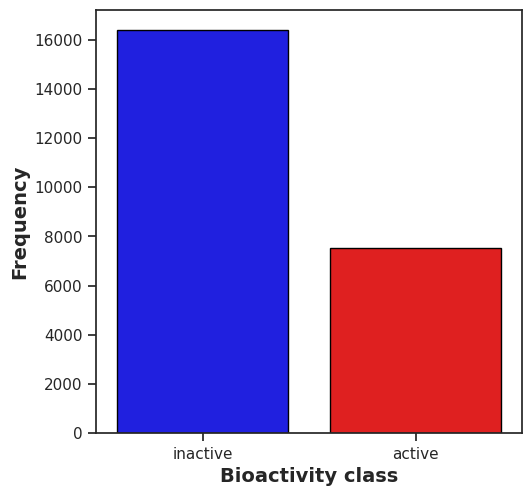

In [27]:
plt.figure(figsize=(5.5, 5.5))

palette = {
    'inactive': 'blue',
    'active': 'red'
}

sns.countplot(x='bioactivity_class', data=df_2class, edgecolor='black', palette= palette)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('Frequency', fontsize=14, fontweight='bold')

plt.savefig('plot_bioactivity_class.jpg', dpi=300, bbox_inches='tight')

/usr/local/lib/python3.12/dist-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)
/usr/local/lib/python3.12/dist-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


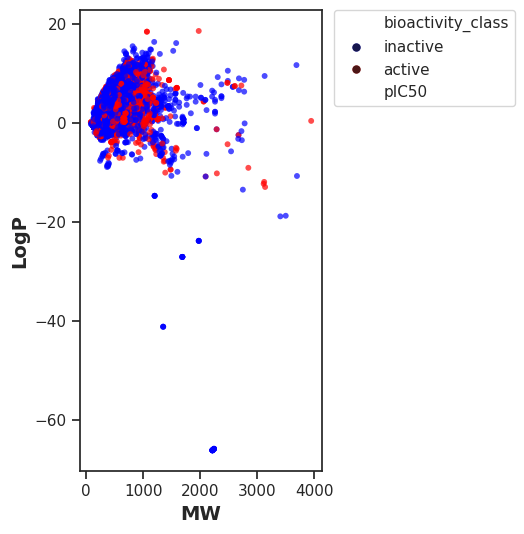

In [28]:
plt.figure(figsize=(5.5, 5.5))

palette = {
    'active': 'red',
    'inactive': 'blue'
}

sns.scatterplot(
    x='MW', y='LogP',
    data=df_2class,
    hue='bioactivity_class',
    size='pIC50',
    edgecolor='black',
    palette=palette,
    alpha=0.7
)

plt.xlabel('MW', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')

plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0)

plt.tight_layout()
plt.savefig('plot_MW_vs_LogP.jpg', bbox_inches='tight', dpi=300)

/tmp/ipython-input-1035/677405892.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'bioactivity_class', y = 'pIC50', data = df_2class, palette= palette)


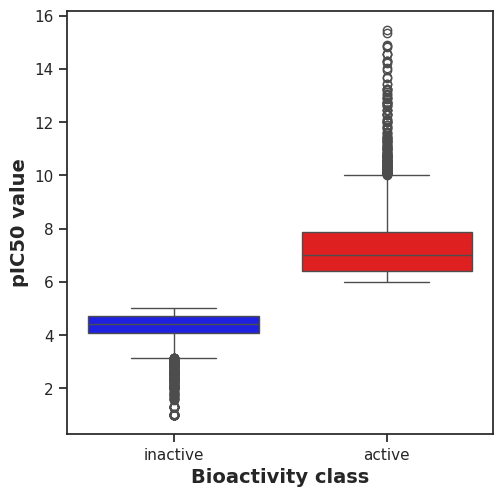

In [ ]:
plt.figure(figsize=(5.5, 5.5))

palette = {
    'inactive': 'blue',
    'active': 'red'
}

sns.boxplot(x = 'bioactivity_class', y = 'pIC50', data = df_2class, palette= palette)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('pIC50 value', fontsize=14, fontweight='bold')

plt.savefig('plot_ic50.jpg', dpi=300, bbox_inches='tight')

In [ ]:
def mannwhitney(descriptor, verbose=False):
  # https://machinelearningmastery.com/nonparametric-statistical-significance-tests-in-python/
  from numpy.random import seed
  from numpy.random import randn
  from scipy.stats import mannwhitneyu

# seed the random number generator
  seed(1)

# actives and inactives
  selection = [descriptor, 'bioactivity_class']
  df = df_2class[selection]
  active = df[df.bioactivity_class == 'active']
  active = active[descriptor]

  selection = [descriptor, 'bioactivity_class']
  df = df_2class[selection]
  inactive = df[df.bioactivity_class == 'inactive']
  inactive = inactive[descriptor]

# compare samples
  stat, p = mannwhitneyu(active, inactive)
  #print('Statistics=%.3f, p=%.3f' % (stat, p))

# interpret
  alpha = 0.05
  if p > alpha:
    interpretation = 'Same distribution (fail to reject H0)'
  else:
    interpretation = 'Different distribution (reject H0)'

  results = pd.DataFrame({'Descriptor':descriptor,
                          'Statistics':stat,
                          'p':p,
                          'alpha':alpha,
                          'Interpretation':interpretation}, index=[0])
  filename = 'mannwhitneyu_' + descriptor + '.csv'
  results.to_csv(filename)

  return results

In [ ]:
mannwhitney('pIC50')

,Descriptor,Statistics,p,alpha,Interpretation
0,pIC50,123586827.0,0.0,0.05,Different distribution (reject H0)


/tmp/ipython-input-1035/3444538188.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'bioactivity_class', y = 'MW', data = df_2class, palette= palette)


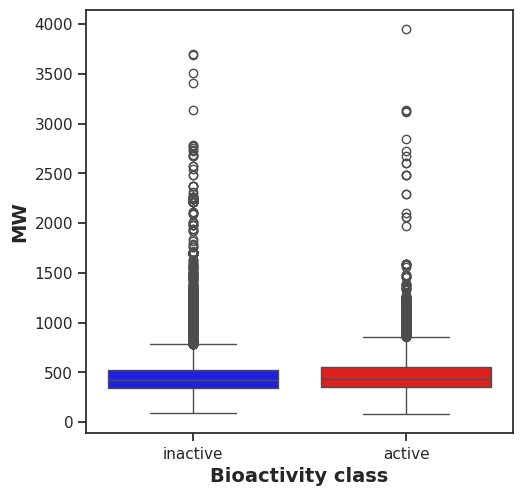

In [ ]:
plt.figure(figsize=(5.5, 5.5))

palette = {
    'inactive': 'blue',
    'active': 'red'
}

sns.boxplot(x = 'bioactivity_class', y = 'MW', data = df_2class, palette= palette)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('MW', fontsize=14, fontweight='bold')

plt.savefig('plot_MW.jpg', dpi=300, bbox_inches='tight')

In [ ]:
mannwhitney('MW')

,Descriptor,Statistics,p,alpha,Interpretation
0,MW,66339372.5,5.358576e-20,0.05,Different distribution (reject H0)


/tmp/ipython-input-1035/2253813961.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'bioactivity_class', y = 'LogP', data = df_2class, palette= palette)


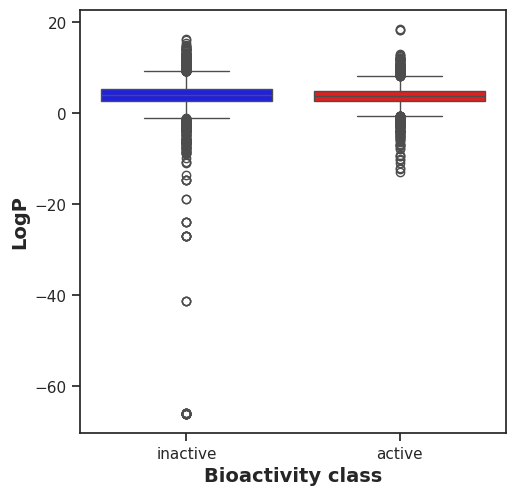

In [ ]:
plt.figure(figsize=(5.5, 5.5))

palette = {
    'inactive': 'blue',
    'active': 'red'
}

sns.boxplot(x = 'bioactivity_class', y = 'LogP', data = df_2class, palette= palette)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')

plt.savefig('plot_LogP.jpg', dpi=300, bbox_inches='tight' )

In [ ]:
mannwhitney('LogP')

,Descriptor,Statistics,p,alpha,Interpretation
0,LogP,58398669.5,8.044767e-12,0.05,Different distribution (reject H0)


/tmp/ipython-input-1035/2268334598.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'bioactivity_class', y = 'NumHDonors', data = df_2class, palette=palette)


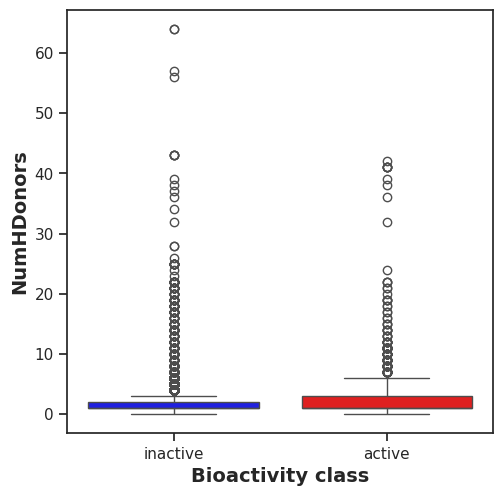

In [ ]:
plt.figure(figsize=(5.5, 5.5))

palette = {
    'inactive': 'blue',
    'active': 'red'
}

sns.boxplot(x = 'bioactivity_class', y = 'NumHDonors', data = df_2class, palette=palette)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHDonors', fontsize=14, fontweight='bold')

plt.savefig('plot_NumHDonors.jpg', dpi=300, bbox_inches='tight')

In [ ]:
mannwhitney('NumHDonors')

,Descriptor,Statistics,p,alpha,Interpretation
0,NumHDonors,66060119.5,1.025227e-18,0.05,Different distribution (reject H0)


/tmp/ipython-input-1035/2807347897.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'bioactivity_class', y = 'NumHAcceptors', data = df_2class, palette=palette)


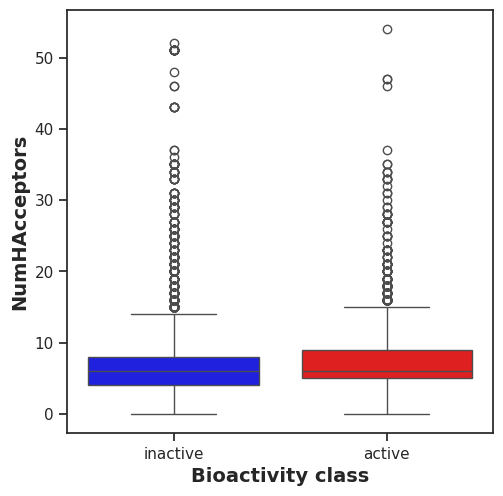

In [ ]:
plt.figure(figsize=(5.5, 5.5))
palette = {
    'inactive': 'blue',
    'active': 'red'
}

sns.boxplot(x = 'bioactivity_class', y = 'NumHAcceptors', data = df_2class, palette=palette)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHAcceptors', fontsize=14, fontweight='bold')

plt.savefig('plot_NumHAcceptors.jpg', dpi=300, bbox_inches='tight')

In [ ]:
mannwhitney('NumHAcceptors')

,Descriptor,Statistics,p,alpha,Interpretation
0,NumHAcceptors,72101037.5,5.954189e-97,0.05,Different distribution (reject H0)


In [ ]:
! zip -r results.zip . -i *.csv *.pdf

  adding: mannwhitneyu_NumHDonors.csv (deflated 11%)
  adding: filtered_bioactivity_data.csv (deflated 80%)
  adding: mannwhitneyu_LogP.csv (deflated 8%)
  adding: mannwhitneyu_pIC50.csv (deflated 8%)
  adding: mannwhitneyu_NumHAcceptors.csv (deflated 10%)
  adding: bioactivity_smilespreprocessed_data.csv (deflated 85%)
  adding: mannwhitneyu_MW.csv (deflated 10%)
